## Business Understanding
* **Business Goal :** : The primary business goal is to increase customer satisfaction and loyalty by identifying key factors that influence passenger satisfaction. By predicting wheather a passenger wii be satisfied or dissatisfied based on various service factors, the airline can proactively address issues, enhance the overall customer experience, and retain more customers.



* **Client Reference :** Potential Clients (Any Airline Companies)

#### Business goal affecting features :

Features that can affect price estimation

- Gender 
- Age
- Type of Travel
- Class
- Flight Distance
- Inflight wifi service
- Departure/Arrival time convenient
- Departure Dely in Minutes
- Arrival Delay in Minutes
- On-board serivice
- Leg room service
- Baggage handling
- Checkin serivice
- Inflight service
- Cleanliness
- satisfaction

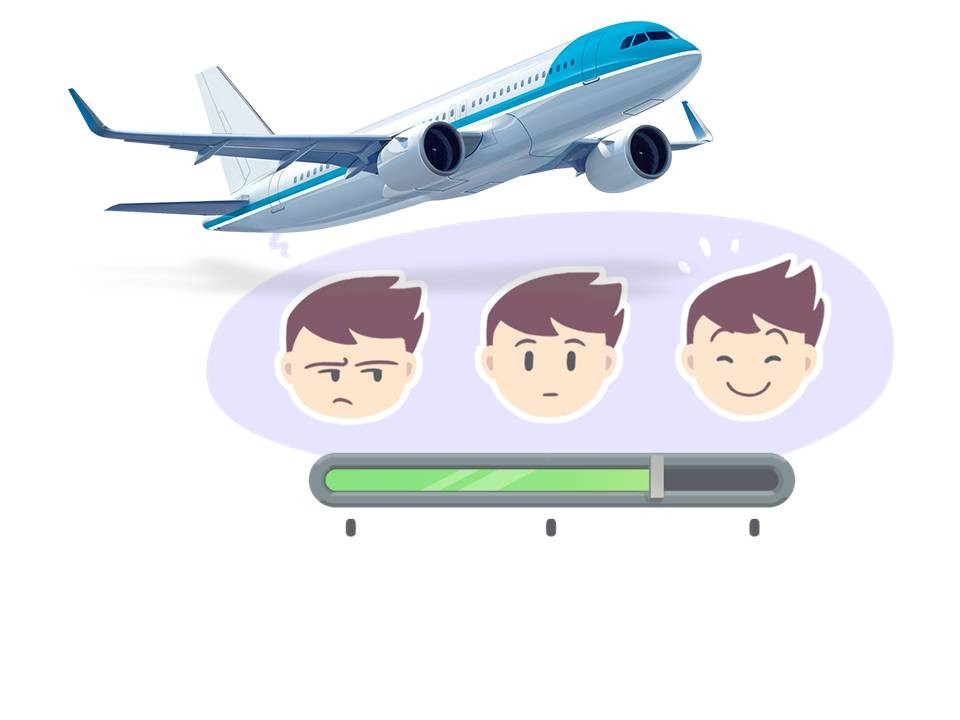

### TOC <a id='menu'>
    
* [0. Data](#raw)
* [1. Data Validation](#dv)
* [2. EDA](#eda)
* [3. Missing Values & Outliers](#naot)
* [4. Predictive Modelling](#pm)
    * [4.1 x & y](#xy)
    * [4.2 Feature Engineering of x](#fe)
    * [4.3 Train-Test Split of x & y](#tts)
    * [4.4 Training Model](#tm)
    * [4.5 Model Evaluation](#me)
* [5. Real Time Prediction](#rtp)

### 0.Data <a id='raw'>
[Back to Menu](#menu)

In [1]:
import pandas as pd

import numpy as np 

import warnings
warnings.filterwarnings("ignore")

In [2]:
#Loading Data using pandas methods, with variable/object name 'raw'

rawdata = pd.read_csv("Airline Passenger Satisfaction.csv")

In [3]:
rawdata

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103899,103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied


- **This data contains Airline passenger info**

- We have a total of 103904 records/rows & 10 features/columns

-  Columns info:

Column Name|Description
---------------|---------------
Unnamed:0| index column
id|Unique identifier for each passenger
Gender|Gender of the passenger 
Customer Type| Indicates whether a customer is a loyal customer or a first time flyer
Age|Age of the passenger
Type of Travel|Purpose of the travel
Class|Travel class of the passenger
Flight Distance|Distance covered during the the flight(in miles or kilometers)
Inflight wifi service|Passenger rating of the inflight wifi service
Departure/Arrival time convenient|Passenger rating on the convenience of departure and arrival times
Ease of Online booking|Passenger rating of the online booking process
Gate location|Passenger rating of the gate location's convenience
Food and drink|Passenger rating of the food and drink quality
Online boarding|Passenger rating of the online boarding process
Seat comfort|Passenger rating of seat comfort during the flight
Inflight entertainment|Passenger rating of the entertainment options
On-board service|Passenger rating of overall onboard service
Leg room service|Passenger rating of the legroom space available
Baggage handling|Passenger rating of baggage handling service
Checkin service|Passenger rating of the overall inflight service
Inflight service|Passenger rating of the overall inflight service
Cleanliness|Passenger rating of the aircraft's cleanliness
Departure Delay Minutes|Delay time of the departure in minutes
Arrival Delay in Minutes|Delay time of the departure in minutes
satisfaction|Overall satisfaction level of the passenger


#### Basic Checks of Dataset

In [4]:
rawdata.shape

(103904, 25)

In [5]:
print("First five rows of Dataset:")
display(rawdata.head())
print("Last five rows of Dataset:")
rawdata.tail()

First five rows of Dataset:


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


Last five rows of Dataset:


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
103899,103899,94171,Female,disloyal Customer,23,Business travel,Eco,192,2,1,...,2,3,1,4,2,3,2,3,0.0,neutral or dissatisfied
103900,103900,73097,Male,Loyal Customer,49,Business travel,Business,2347,4,4,...,5,5,5,5,5,5,4,0,0.0,satisfied
103901,103901,68825,Male,disloyal Customer,30,Business travel,Business,1995,1,1,...,4,3,2,4,5,5,4,7,14.0,neutral or dissatisfied
103902,103902,54173,Female,disloyal Customer,22,Business travel,Eco,1000,1,1,...,1,4,5,1,5,4,1,0,0.0,neutral or dissatisfied
103903,103903,62567,Male,Loyal Customer,27,Business travel,Business,1723,1,3,...,1,1,1,4,4,3,1,0,0.0,neutral or dissatisfied


In [6]:
rawdata.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

#### Rename of columns

In [7]:
rawdata.columns = [col.replace(" ","_") for col in rawdata.columns]

In [8]:
print("Column data check (Null Values & Data Types):")
print()
rawdata.info()

Column data check (Null Values & Data Types):

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed:_0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer_Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type_of_Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight_Distance                    103904 non-null  int64  
 8   Inflight_wifi_service              103904 non-null  int64  
 9   Departure/Arrival_time_convenient  103904 non-null  int64  
 10  Ease_of_Online_booking             103904 non-null  int64

In [9]:
print("Missing Values Count of Each Column:")
print()
rawdata.isnull().sum()

Missing Values Count of Each Column:



Unnamed:_0                             0
id                                     0
Gender                                 0
Customer_Type                          0
Age                                    0
Type_of_Travel                         0
Class                                  0
Flight_Distance                        0
Inflight_wifi_service                  0
Departure/Arrival_time_convenient      0
Ease_of_Online_booking                 0
Gate_location                          0
Food_and_drink                         0
Online_boarding                        0
Seat_comfort                           0
Inflight_entertainment                 0
On-board_service                       0
Leg_room_service                       0
Baggage_handling                       0
Checkin_service                        0
Inflight_service                       0
Cleanliness                            0
Departure_Delay_in_Minutes             0
Arrival_Delay_in_Minutes             310
satisfaction    

### 1. Data Validating & Cleaning <a id='dv'>
[Back to Menu](#menu)
                                    

In [10]:
# Taking copy of data

raw = rawdata.copy()

#### Duplicated Rows Data

In [11]:
# As python is case sensitive, converting object data type columns into lower case

for col in raw.columns:
    if raw[col].dtype=="object":
        raw[col] = raw[col].str.lower()

In [12]:
raw.head()

,Unnamed:_0,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,male,disloyal customer,25,business travel,business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,female,loyal customer,26,business travel,business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,female,loyal customer,25,business travel,business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,male,loyal customer,61,business travel,business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [13]:
# Checking Duplicated rowss

raw[raw.duplicated()]

,Unnamed:_0,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction


- Data is valid there is no duplicates in the data

- #### Validating Each Columns Data

In [14]:
raw.columns

Index(['Unnamed:_0', 'id', 'Gender', 'Customer_Type', 'Age', 'Type_of_Travel',
       'Class', 'Flight_Distance', 'Inflight_wifi_service',
       'Departure/Arrival_time_convenient', 'Ease_of_Online_booking',
       'Gate_location', 'Food_and_drink', 'Online_boarding', 'Seat_comfort',
       'Inflight_entertainment', 'On-board_service', 'Leg_room_service',
       'Baggage_handling', 'Checkin_service', 'Inflight_service',
       'Cleanliness', 'Departure_Delay_in_Minutes', 'Arrival_Delay_in_Minutes',
       'satisfaction'],
      dtype='object')


**Unnamed:_0**

In [15]:
raw = raw.drop(columns=['Unnamed:_0'])

In [16]:
raw.head()

,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,male,disloyal customer,25,business travel,business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,female,loyal customer,26,business travel,business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,female,loyal customer,25,business travel,business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,male,loyal customer,61,business travel,business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


- Data is valid and belongs to column

**id**

In [17]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.id.nunique())

print()

print("Unique Classes:")
raw.id.unique()

Number of Unique Classes in Column: 103904

Unique Classes:


array([ 70172,   5047, 110028, ...,  68825,  54173,  62567], dtype=int64)

- Data is valid and belongs to column

In [18]:
raw.head(2)

,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,...,Inflight_entertainment,On-board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,male,disloyal customer,25,business travel,business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied


**Gender**

In [19]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Gender.nunique())

print()

print("Unique Classes:")
raw.Gender.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['male', 'female'], dtype=object)

- Data is valid and belongs to column

**Customer_Type**

In [20]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Customer_Type.nunique())

print()

print("Unique Classes:")
raw.Customer_Type.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['loyal customer', 'disloyal customer'], dtype=object)

- Data is valid and belongs to column

**Age**

In [21]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Age.nunique())

print()

print("Unique Classes:")
raw.Age.unique()

Number of Unique Classes in Column: 75

Unique Classes:


array([13, 25, 26, 61, 47, 52, 41, 20, 24, 12, 53, 33, 45, 38,  9, 17, 43,
       58, 23, 57, 49, 36, 22, 31, 15, 35, 67, 37, 40, 34, 39, 50, 29, 54,
       21, 28, 27, 69, 60, 48, 59, 46, 30, 66, 64, 44, 51, 32, 19, 42, 16,
       11, 62,  8, 56, 68, 55, 18, 65, 72, 70, 63, 10,  7, 14, 80, 74, 71,
       85, 73, 76, 77, 75, 79, 78], dtype=int64)

- Data is valid and belongs to column

**Type_of_Travel**

In [22]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Type_of_Travel.nunique())

print()

print("Unique Classes:")
raw.Type_of_Travel.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['personal travel', 'business travel'], dtype=object)

- Data is valid and belongs to column

**Class**

In [23]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Class.nunique())

print()

print("Unique Classes:")
raw.Class.unique()

Number of Unique Classes in Column: 3

Unique Classes:


array(['eco plus', 'business', 'eco'], dtype=object)

- Data is valid and belongs to column

**Flight_Distance**

In [24]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Flight_Distance.nunique())

print()

print("Unique Classes:")
raw.Flight_Distance.unique()

Number of Unique Classes in Column: 3802

Unique Classes:


array([ 460,  235, 1142, ...,  974, 1479,  400], dtype=int64)

- Data is valid and belongs to column

**Inflight_wifi_service**

In [25]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Inflight_wifi_service.nunique())

print()

print("Unique Classes:")
raw.Inflight_wifi_service.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([3, 2, 4, 1, 5, 0], dtype=int64)

- Data is valid belongs to column

**Departure/Arrival_time_convenient**

In [26]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Departure_Delay_in_Minutes.nunique())

print()

print("Unique Classes:")
raw.Departure_Delay_in_Minutes.unique()

Number of Unique Classes in Column: 446

Unique Classes:


array([  25,    1,    0,   11,    9,    4,   28,   43,   49,    7,   17,
         52,   54,   27,   18,   19,    3,  109,   23,    8,   14,   10,
         51,   39,   13,   30,   64,   20,   45,   44,   31,   81,   35,
         67,   22,   40,   91,   21,   15,   29,  105,   12,  162,   24,
        141,    6,   34,    2,   97,   16,   99,   37,   66,   53,   36,
        209,   60,  149,   26,    5,   59,   62,  113,   38,   83,  176,
         46,   73,  199,   56,   93,   70,   80,   96,   57,   95,   74,
        172,   63,  175,  143,   48,   47,  101,  118,   76,  220,   33,
         55,  232,  170,  173,  124,  112,   94,  243,  128,   92,  270,
         90,  110,   50,  144,   71,  315,  158,   88,   65,  111,   32,
        156,   41,  154,  150,  228,   72,  137,  126,  161,   42,  174,
        103,  313,  136,  160,  412,   69,  185,  114,  135,  142,  147,
         85,  235,  125,  391,   84,  138,  102,  196,  140,   77,  187,
        131,   82,  100,   86,  165,   87,  129,  2

**Ease_of_Online_booking**

In [27]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Ease_of_Online_booking.nunique())

print()

print("Unique Classes:")
raw.Ease_of_Online_booking.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([3, 2, 5, 4, 1, 0], dtype=int64)

- Data is valid and belongs to column

**Gate_location**

In [28]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Gate_location.nunique())

print()

print("Unique Classes:")
raw.Gate_location.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([1, 3, 2, 5, 4, 0], dtype=int64)

- Data is valid and belongs to column

**Food_and_drink**

In [29]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Food_and_drink.nunique())

print()

print("Unique Classes:")
raw.Food_and_drink.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([5, 1, 2, 4, 3, 0], dtype=int64)

- Data is valid and belongs to column

**Online_boarding**

In [30]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Online_boarding.nunique())

print()

print("Unique Classes:")
raw.Online_boarding.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([3, 5, 2, 1, 4, 0], dtype=int64)

- Data is valid and belongs to column

**Seat_comfort**

In [31]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Seat_comfort.nunique())

print()

print("Unique Classes:")
raw.Seat_comfort.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([5, 1, 2, 3, 4, 0], dtype=int64)

- Data is valid and belongs to column

**Inflight_entertainment**

In [32]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Inflight_entertainment.nunique())

print()

print("Unique Classes:")
raw.Inflight_entertainment.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([5, 1, 2, 3, 4, 0], dtype=int64)

- Data is valid and belongs to column

**On-board_service**

In [33]:
# The column name contains special characte it has to to be removed
raw = raw.rename(columns={'On-board_service':'On_board_service'})

In [34]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.On_board_service.nunique())

print()

print("Unique Classes:")
raw.On_board_service.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([4, 1, 2, 3, 5, 0], dtype=int64)

- Data is valid and belongs to column data

**Leg_room_service**

In [35]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Leg_room_service.nunique())

print()

print("Unique Classes:")
raw.Leg_room_service.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([3, 5, 4, 2, 1, 0], dtype=int64)

- Data is valid and belongs to column

**Baggage_handling**

In [36]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Baggage_handling.nunique())

print()

print("Unique Classes:")
raw.Baggage_handling.unique()

Number of Unique Classes in Column: 5

Unique Classes:


array([4, 3, 5, 1, 2], dtype=int64)

- Data is valid and belongs to column

**Checkin_service**

In [37]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Checkin_service.nunique())

print()

print("Unique Classes:")
raw.Checkin_service.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([4, 1, 3, 5, 2, 0], dtype=int64)

- Data is valid and belongs to column

**Inflight_service**

In [38]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Inflight_service.nunique())

print()

print("Unique Classes:")
raw.Inflight_service.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([5, 4, 3, 1, 2, 0], dtype=int64)

- Data is valid and belongs to column

**Cleanliness**

In [39]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Cleanliness.nunique())

print()

print("Unique Classes:")
raw.Cleanliness.unique()

Number of Unique Classes in Column: 6

Unique Classes:


array([5, 1, 2, 3, 4, 0], dtype=int64)

- Data is valid and belongs to column

**Departure_Delay_in_Minutes**

In [40]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Departure_Delay_in_Minutes.nunique())

print()

print("Unique Classes:")
raw.Departure_Delay_in_Minutes.unique()

Number of Unique Classes in Column: 446

Unique Classes:


array([  25,    1,    0,   11,    9,    4,   28,   43,   49,    7,   17,
         52,   54,   27,   18,   19,    3,  109,   23,    8,   14,   10,
         51,   39,   13,   30,   64,   20,   45,   44,   31,   81,   35,
         67,   22,   40,   91,   21,   15,   29,  105,   12,  162,   24,
        141,    6,   34,    2,   97,   16,   99,   37,   66,   53,   36,
        209,   60,  149,   26,    5,   59,   62,  113,   38,   83,  176,
         46,   73,  199,   56,   93,   70,   80,   96,   57,   95,   74,
        172,   63,  175,  143,   48,   47,  101,  118,   76,  220,   33,
         55,  232,  170,  173,  124,  112,   94,  243,  128,   92,  270,
         90,  110,   50,  144,   71,  315,  158,   88,   65,  111,   32,
        156,   41,  154,  150,  228,   72,  137,  126,  161,   42,  174,
        103,  313,  136,  160,  412,   69,  185,  114,  135,  142,  147,
         85,  235,  125,  391,   84,  138,  102,  196,  140,   77,  187,
        131,   82,  100,   86,  165,   87,  129,  2

- Data is valid and belongs to column

**Arrival_Delay_in_Minutes**

In [41]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.Arrival_Delay_in_Minutes.nunique())

print()

print("Unique Classes:")
raw.Arrival_Delay_in_Minutes.unique()

Number of Unique Classes in Column: 455

Unique Classes:


array([1.800e+01, 6.000e+00, 0.000e+00, 9.000e+00, 2.300e+01, 8.000e+00,
       3.500e+01, 5.100e+01, 1.000e+01, 5.000e+00, 4.000e+00, 2.900e+01,
       4.400e+01, 2.800e+01, 1.200e+01, 1.200e+02, 2.400e+01, 1.000e+00,
       2.000e+01, 3.100e+01, 1.500e+01, 4.800e+01, 2.600e+01, 4.900e+01,
       2.000e+00, 3.700e+01, 5.000e+01, 3.000e+00, 1.900e+01, 7.200e+01,
       1.100e+01, 3.400e+01, 6.200e+01, 2.700e+01, 5.200e+01, 1.300e+01,
       8.200e+01, 3.000e+01, 1.600e+01, 7.000e+00, 1.220e+02, 1.790e+02,
       1.250e+02, 1.700e+01,       nan, 8.900e+01, 1.010e+02, 1.400e+01,
       6.100e+01, 3.200e+01, 3.300e+01, 4.100e+01, 1.910e+02, 1.380e+02,
       5.300e+01, 2.200e+01, 5.700e+01, 6.500e+01, 7.600e+01, 1.070e+02,
       9.200e+01, 1.640e+02, 2.100e+01, 4.000e+01, 5.500e+01, 1.850e+02,
       6.300e+01, 7.700e+01, 8.600e+01, 9.100e+01, 1.000e+02, 5.400e+01,
       3.600e+01, 7.000e+01, 1.390e+02, 6.700e+01, 1.630e+02, 1.280e+02,
       1.800e+02, 9.300e+01, 1.210e+02, 4.500e+01, 

- Data is valid and belongs to column

**satisfaction**

In [42]:
# Checking number of unique values & unique values in col data

print("Number of Unique Classes in Column:", raw.satisfaction.nunique())

print()

print("Unique Classes:")
raw.satisfaction.unique()

Number of Unique Classes in Column: 2

Unique Classes:


array(['neutral or dissatisfied', 'satisfied'], dtype=object)

- Data is valid and belongs to column

**Final Validated data**

In [43]:
raw.head(3)

,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,...,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,male,disloyal customer,25,business travel,business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,female,loyal customer,26,business travel,business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied


### 2. EDA (Data Understanding)<a id=eda>
    
[Back to Top](#menu)

* In EDA we can do Data Analysis in two methods
    - Uni-Variate Analysis (Study of Individual column Data)
        - Descriptive + Visual Analysis
    - Bi-Varaite Analysis (Study data between two columns)
        - Descriptive + Visual Analysis
    - Multi-Variate Analysis (Study data between three or more columns)
        - Descriptive Stats (For Regression project , corr matrix)

In [44]:
data = raw.copy()

In [45]:
data.head(2)

,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,...,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,male,disloyal customer,25,business travel,business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied


#### 2.1 Uni-Variate Analysis

In [46]:
# Visualization libraries

In [47]:
import matplotlib.pyplot as plt

import seaborn as sns

from plotly.offline import init_notebook_mode
init_notebook_mode(connected=True)

import plotly.express as px


In [48]:
!pip install simple_colors

In [49]:
from simple_colors import *

In [50]:
from DSProjLib import Eda

Column Name: id

*****************************************
          Descriptive Stats              
*****************************************

Mean: 64924.21
Median: 64856.5
Mode of the id Col: 1

Min & Max: (1, 129880)
Standard Deviation: 37463.81

Summary:
count    103904.00
mean      64924.21
std       37463.81
min           1.00
25%       32533.75
50%       64856.50
75%       97368.25
max      129880.00
Name: id, dtype: float64

Skewness: 0.0
Kurtosis: -1.2

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



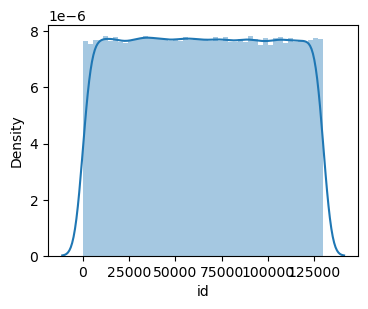

Column Name: Gender

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['male' 'female']

Number of Classes: 2

Value Counts of each class:
female    52727
male      51177
Name: Gender, dtype: int64

Each Class percentage:
female    50.75
male      49.25
Name: Gender, dtype: float64

Mode value: female

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Customer_Type

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['loyal customer' 'disloyal customer']

Number of Classes: 2

Value Counts of each class:
loyal customer       84923
disloyal customer    18981
Name: Customer_Type, dtype: int64

Each Class percentage:
loyal customer       81.73
disloyal customer    18.27
Name: Customer_Type, dtype: float64

Mode value: loyal customer

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Age

*****************************************
          Descriptive Stats              
*****************************************

Mean: 39.38
Median: 40.0
Mode of the Age Col: 39

Min & Max: (7, 85)
Standard Deviation: 15.11

Summary:
count    103904.00
mean         39.38
std          15.11
min           7.00
25%          27.00
50%          40.00
75%          51.00
max          85.00
Name: Age, dtype: float64

Skewness: -0.0
Kurtosis: -0.72

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



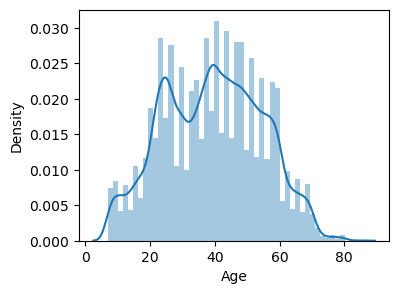

Column Name: Type_of_Travel

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['personal travel' 'business travel']

Number of Classes: 2

Value Counts of each class:
business travel    71655
personal travel    32249
Name: Type_of_Travel, dtype: int64

Each Class percentage:
business travel    68.96
personal travel    31.04
Name: Type_of_Travel, dtype: float64

Mode value: business travel

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Class

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['eco plus' 'business' 'eco']

Number of Classes: 3

Value Counts of each class:
business    49665
eco         46745
eco plus     7494
Name: Class, dtype: int64

Each Class percentage:
business    47.80
eco         44.99
eco plus     7.21
Name: Class, dtype: float64

Mode value: business

*****************************************
      Visual Analysis - Pie Charts      
*****************************************




Column Name: Flight_Distance

*****************************************
          Descriptive Stats              
*****************************************

Mean: 1189.45
Median: 843.0
Mode of the Flight_Distance Col: 337

Min & Max: (31, 4983)
Standard Deviation: 997.15

Summary:
count    103904.00
mean       1189.45
std         997.15
min          31.00
25%         414.00
50%         843.00
75%        1743.00
max        4983.00
Name: Flight_Distance, dtype: float64

Skewness: 1.11
Kurtosis: 0.27

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



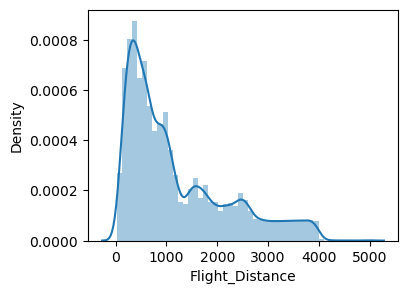

Column Name: Inflight_wifi_service

*****************************************
          Descriptive Stats              
*****************************************

Mean: 2.73
Median: 3.0
Mode of the Inflight_wifi_service Col: 3

Min & Max: (0, 5)
Standard Deviation: 1.33

Summary:
count    103904.00
mean          2.73
std           1.33
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Inflight_wifi_service, dtype: float64

Skewness: 0.04
Kurtosis: -0.85

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



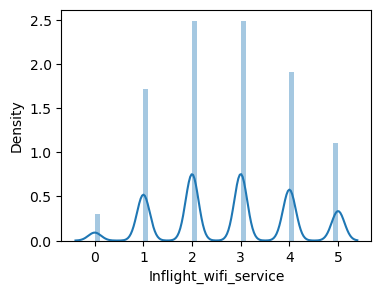

Column Name: Departure/Arrival_time_convenient

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.06
Median: 3.0
Mode of the Departure/Arrival_time_convenient Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.53

Summary:
count    103904.00
mean          3.06
std           1.53
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Departure/Arrival_time_convenient, dtype: float64

Skewness: -0.33
Kurtosis: -1.04

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



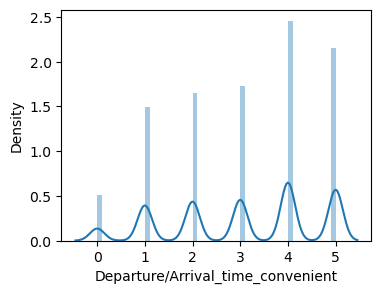

Column Name: Ease_of_Online_booking

*****************************************
          Descriptive Stats              
*****************************************

Mean: 2.76
Median: 3.0
Mode of the Ease_of_Online_booking Col: 3

Min & Max: (0, 5)
Standard Deviation: 1.4

Summary:
count    103904.00
mean          2.76
std           1.40
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Ease_of_Online_booking, dtype: float64

Skewness: -0.02
Kurtosis: -0.91

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



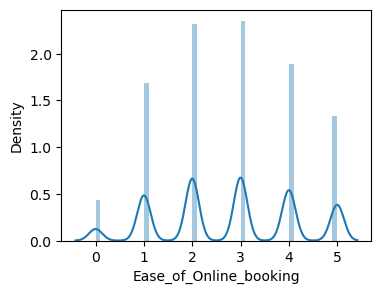

Column Name: Gate_location

*****************************************
          Descriptive Stats              
*****************************************

Mean: 2.98
Median: 3.0
Mode of the Gate_location Col: 3

Min & Max: (0, 5)
Standard Deviation: 1.28

Summary:
count    103904.00
mean          2.98
std           1.28
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Gate_location, dtype: float64

Skewness: -0.06
Kurtosis: -1.03

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



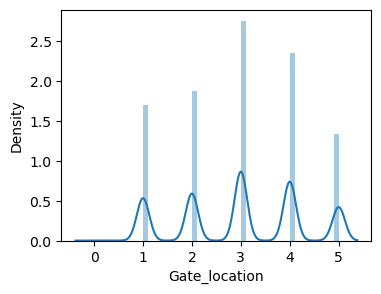

Column Name: Food_and_drink

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.2
Median: 3.0
Mode of the Food_and_drink Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.33

Summary:
count    103904.00
mean          3.20
std           1.33
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Food_and_drink, dtype: float64

Skewness: -0.15
Kurtosis: -1.15

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



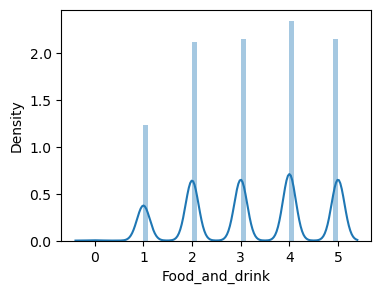

Column Name: Online_boarding

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.25
Median: 3.0
Mode of the Online_boarding Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.35

Summary:
count    103904.00
mean          3.25
std           1.35
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Online_boarding, dtype: float64

Skewness: -0.45
Kurtosis: -0.7

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



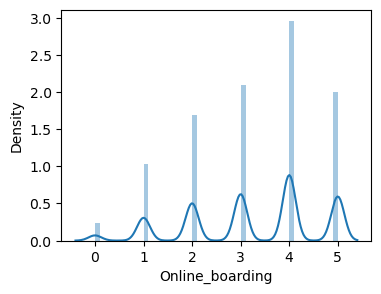

Column Name: Seat_comfort

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.44
Median: 4.0
Mode of the Seat_comfort Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.32

Summary:
count    103904.00
mean          3.44
std           1.32
min           0.00
25%           2.00
50%           4.00
75%           5.00
max           5.00
Name: Seat_comfort, dtype: float64

Skewness: -0.48
Kurtosis: -0.93

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



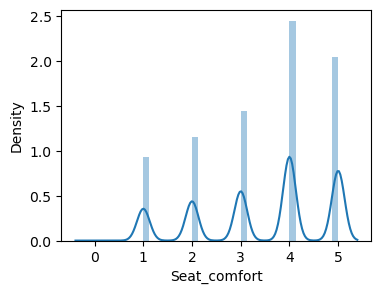

Column Name: Inflight_entertainment

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.36
Median: 4.0
Mode of the Inflight_entertainment Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.33

Summary:
count    103904.00
mean          3.36
std           1.33
min           0.00
25%           2.00
50%           4.00
75%           4.00
max           5.00
Name: Inflight_entertainment, dtype: float64

Skewness: -0.37
Kurtosis: -1.06

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



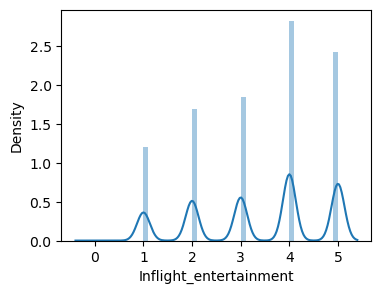

Column Name: On_board_service

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.38
Median: 4.0
Mode of the On_board_service Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.29

Summary:
count    103904.00
mean          3.38
std           1.29
min           0.00
25%           2.00
50%           4.00
75%           4.00
max           5.00
Name: On_board_service, dtype: float64

Skewness: -0.42
Kurtosis: -0.89

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



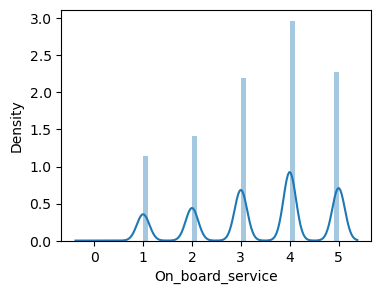

Column Name: Leg_room_service

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.35
Median: 4.0
Mode of the Leg_room_service Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.32

Summary:
count    103904.00
mean          3.35
std           1.32
min           0.00
25%           2.00
50%           4.00
75%           4.00
max           5.00
Name: Leg_room_service, dtype: float64

Skewness: -0.35
Kurtosis: -0.98

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



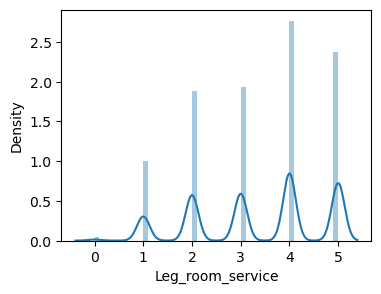

Column Name: Baggage_handling

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.63
Median: 4.0
Mode of the Baggage_handling Col: 4

Min & Max: (1, 5)
Standard Deviation: 1.18

Summary:
count    103904.00
mean          3.63
std           1.18
min           1.00
25%           3.00
50%           4.00
75%           5.00
max           5.00
Name: Baggage_handling, dtype: float64

Skewness: -0.68
Kurtosis: -0.39

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



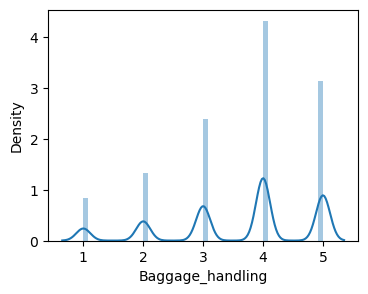

Column Name: Checkin_service

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.3
Median: 3.0
Mode of the Checkin_service Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.27

Summary:
count    103904.00
mean          3.30
std           1.27
min           0.00
25%           3.00
50%           3.00
75%           4.00
max           5.00
Name: Checkin_service, dtype: float64

Skewness: -0.36
Kurtosis: -0.83

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



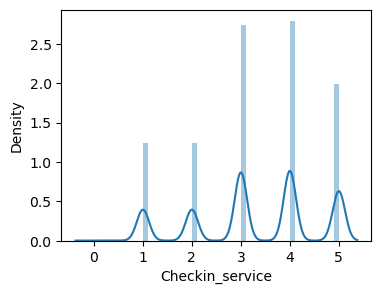

Column Name: Inflight_service

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.64
Median: 4.0
Mode of the Inflight_service Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.18

Summary:
count    103904.00
mean          3.64
std           1.18
min           0.00
25%           3.00
50%           4.00
75%           5.00
max           5.00
Name: Inflight_service, dtype: float64

Skewness: -0.69
Kurtosis: -0.36

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



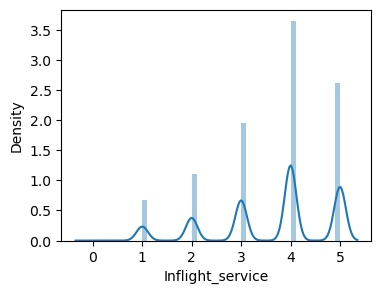

Column Name: Cleanliness

*****************************************
          Descriptive Stats              
*****************************************

Mean: 3.29
Median: 3.0
Mode of the Cleanliness Col: 4

Min & Max: (0, 5)
Standard Deviation: 1.31

Summary:
count    103904.00
mean          3.29
std           1.31
min           0.00
25%           2.00
50%           3.00
75%           4.00
max           5.00
Name: Cleanliness, dtype: float64

Skewness: -0.3
Kurtosis: -1.01

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



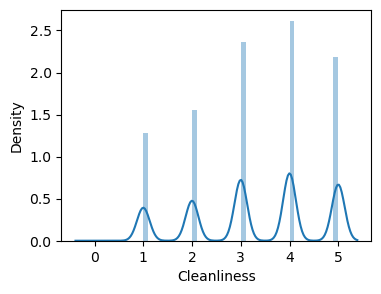

Column Name: Departure_Delay_in_Minutes

*****************************************
          Descriptive Stats              
*****************************************

Mean: 14.82
Median: 0.0
Mode of the Departure_Delay_in_Minutes Col: 0

Min & Max: (0, 1592)
Standard Deviation: 38.23

Summary:
count    103904.00
mean         14.82
std          38.23
min           0.00
25%           0.00
50%           0.00
75%          12.00
max        1592.00
Name: Departure_Delay_in_Minutes, dtype: float64

Skewness: 6.73
Kurtosis: 100.27

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



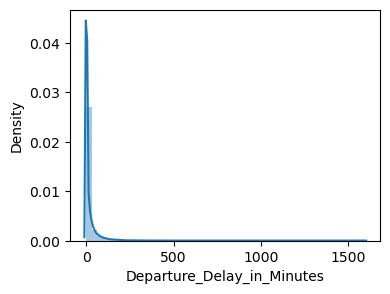

Column Name: Arrival_Delay_in_Minutes

*****************************************
          Descriptive Stats              
*****************************************

Mean: 15.18
Median: 0.0
Mode of the Arrival_Delay_in_Minutes Col: 0.0

Min & Max: (0.0, 1584.0)
Standard Deviation: 38.7

Summary:
count    103594.00
mean         15.18
std          38.70
min           0.00
25%           0.00
50%           0.00
75%          13.00
max        1584.00
Name: Arrival_Delay_in_Minutes, dtype: float64

Skewness: 6.6
Kurtosis: 94.54

********************************************************
 Visual Analysis - Distplot (Histogram + Desnsity plot) 
********************************************************



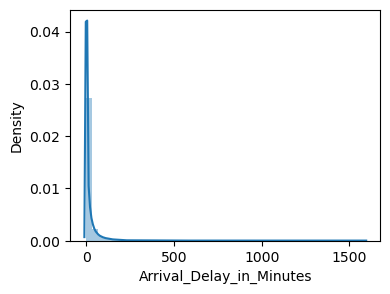

Column Name: satisfaction

*****************************************
          Descriptive Stats              
*****************************************

Classes: ['neutral or dissatisfied' 'satisfied']

Number of Classes: 2

Value Counts of each class:
neutral or dissatisfied    58879
satisfied                  45025
Name: satisfaction, dtype: int64

Each Class percentage:
neutral or dissatisfied    56.67
satisfied                  43.33
Name: satisfaction, dtype: float64

Mode value: neutral or dissatisfied

*****************************************
      Visual Analysis - Pie Charts      
*****************************************



In [51]:
Eda.univariate(data)

**Insights:**

- The minimum value of the id column is 1, and the maximum is 129880
- The dataset has a fairly balanced gender distribution with 50.75% female and 49.25% male passengers
- Majority of the passengers are loyal customers, accounting for 81.73% of the total, while disloyal customers make up only 18.27%
- The passenger's ages ranges from 7 to 85 years, with a mean age of 39.38 years
- The majority of the trips are business-related, with 68.96% of passengers traveling for business and 31.04% for personal reasons
- Business class is the most popular travel class, with 47.80% of passengers choosing it, followed by economy class (44.99%) and economy plus (7.21%). 
- The flight distances vary widely, from as short as 31 miles to as long as 4,983 miles,with a mean of 1,189.45 miles.
- The most common rating for the inflight Wi-Fi service, or the mode, is 3.
- The most frequent rating for the inflight service, with a mode of 4, indicates that many passengers rated it as 4 out of 5, from this we can say that most passengers arre generally satisfied.
- Both departure and arrival delays have a high skewness (>6), indicating that while most flights are on time (median delay of 0 minutes), there are some extreme outliers with significant delays (up to 1,592 minutes for departures and 1,584 minutes for arrivals).
- The majority of passengers (56.67%) are either neutral or dissatisfied, while 43.33% are satisfied with their flight experience. This indicates a relatively high level of dissatisfaction or indifference among the passengers, which could be an area of concern for the airline.
- the fact that many services like food and drink, online boarding, and baggage handling received average ratings suggests that improving these areas could boost overall passenger satisfaction.

#### 2.1 Bi-Variate Analysis

In [52]:
data.head(2)

,id,Gender,Customer_Type,Age,Type_of_Travel,Class,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,...,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,70172,male,loyal customer,13,personal travel,eco plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,male,disloyal customer,25,business travel,business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied


* Combinations of Imp Columns for Bi-Variate analysis
    - Consider columns that can show impact on while prediction of Ad click

**Departure_Delay_in_Minutes vs Arrival_Delay_in_Minutes**

In [53]:
data.corr()

,id,Age,Flight_Distance,Inflight_wifi_service,Departure/Arrival_time_convenient,Ease_of_Online_booking,Gate_location,Food_and_drink,Online_boarding,Seat_comfort,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Inflight_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes
id,1.000000,0.022857,0.095544,-0.021276,-0.002110,0.014163,-0.000606,0.001063,0.055477,0.052903,0.002300,0.055241,0.044634,0.074940,0.079273,0.079346,0.024965,-0.019546,-0.037254
Age,0.022857,1.000000,0.099461,0.017859,0.038125,0.024842,-0.001330,0.023000,0.208939,0.160277,0.076444,0.057594,0.040583,-0.047529,0.035482,-0.049427,0.053611,-0.010152,-0.012147
Flight_Distance,0.095544,0.099461,1.000000,0.007131,-0.020043,0.065717,0.004793,0.056994,0.214869,0.157333,0.128740,0.109526,0.133916,0.063184,0.073072,0.057540,0.093149,0.002158,-0.002426
Inflight_wifi_service,-0.021276,0.017859,0.007131,1.000000,0.343845,0.715856,0.336248,0.134718,0.456970,0.122658,0.209321,0.121500,0.160473,0.120923,0.043193,0.110441,0.132698,-0.017402,-0.019095
Departure/Arrival_time_convenient,-0.002110,0.038125,-0.020043,0.343845,1.000000,0.436961,0.444757,0.004906,0.070119,0.011344,-0.004861,0.068882,0.012441,0.072126,0.093333,0.073318,0.014292,0.001005,-0.000864
Ease_of_Online_booking,0.014163,0.024842,0.065717,0.715856,0.436961,1.000000,0.458655,0.031873,0.404074,0.030014,0.047032,0.038833,0.107601,0.038762,0.011081,0.035272,0.016179,-0.006371,-0.007984
Gate_location,-0.000606,-0.001330,0.004793,0.336248,0.444757,0.458655,1.000000,-0.001159,0.001688,0.003669,0.003517,-0.028373,-0.005873,0.002313,-0.035427,0.001681,-0.003830,0.005467,0.005143
Food_and_drink,0.001063,0.023000,0.056994,0.134718,0.004906,0.031873,-0.001159,1.000000,0.234468,0.574556,0.622512,0.059073,0.032498,0.034746,0.087299,0.033993,0.657760,-0.029926,-0.032524
Online_boarding,0.055477,0.208939,0.214869,0.456970,0.070119,0.404074,0.001688,0.234468,1.000000,0.420211,0.285066,0.155443,0.123950,0.083280,0.204462,0.074573,0.331517,-0.018982,-0.021949
Seat_comfort,0.052903,0.160277,0.157333,0.122658,0.011344,0.030014,0.003669,0.574556,0.420211,1.000000,0.610590,0.131971,0.105559,0.074542,0.191854,0.069218,0.678534,-0.027898,-0.029900


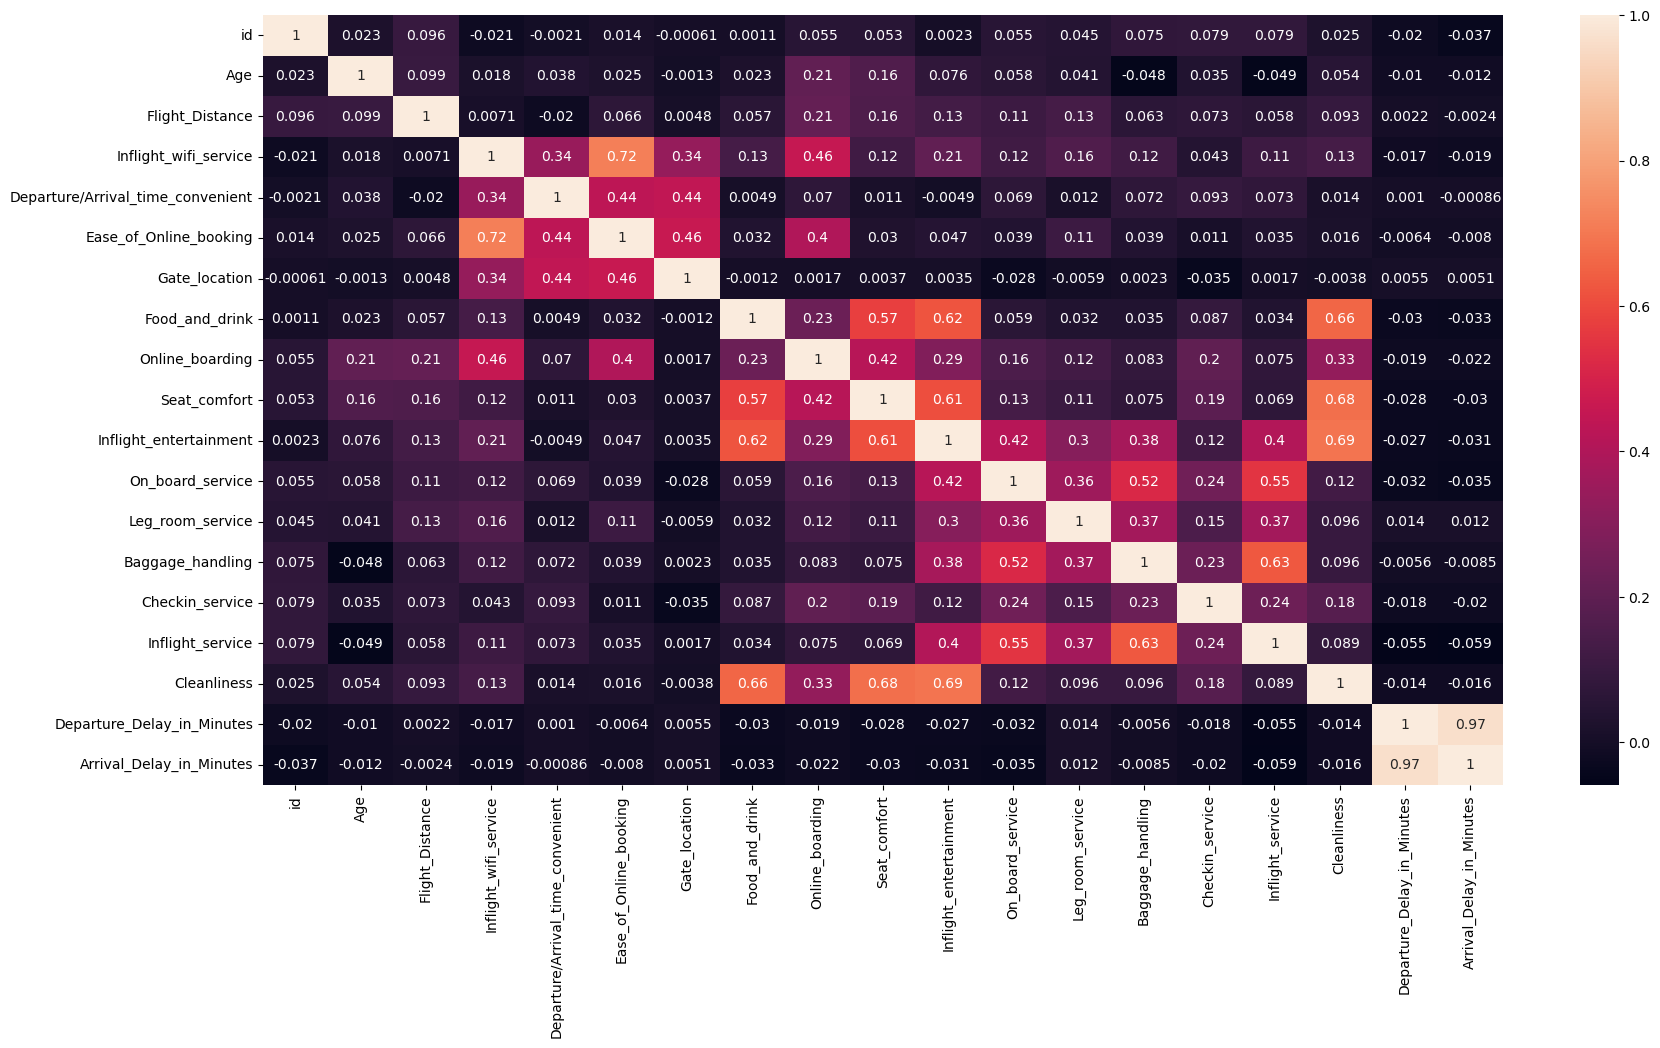

In [54]:
plt.figure(figsize=(20, 10))
sns.heatmap(data.corr(), annot= True)
plt.show()

In [55]:
pd.crosstab(data['Customer_Type'],data['satisfaction'])


satisfaction,neutral or dissatisfied,satisfied
Customer_Type,,
disloyal customer,14489,4492
loyal customer,44390,40533


In [56]:
data = pd.DataFrame({
    'Customer_Type': ['disloyal customer', 'loyal customer'],
    'neutral or dissatisfied': [14489, 44390],
    'satisfied': [4492, 40533]
})

# Calculate the total and percentages

data['Total'] = data['neutral or dissatisfied'] + data['satisfied']
data['Percentage_Neutral_or_Dissatisfied'] = (data['neutral or dissatisfied'] / data['Total']) * 100
data['Percentage_Satisfied'] = (data['satisfied'] / data['Total']) * 100

In [57]:
# Preparing DataFrame with both original and calculated data

display_df = data[['Customer_Type', 'neutral or dissatisfied', 'satisfied', 'Total', 'Percentage_Neutral_or_Dissatisfied', 'Percentage_Satisfied']]

In [58]:
# Displaying the DataFrame

display_df

,Customer_Type,neutral or dissatisfied,satisfied,Total,Percentage_Neutral_or_Dissatisfied,Percentage_Satisfied
0,disloyal customer,14489,4492,18981,76.334229,23.665771
1,loyal customer,44390,40533,84923,52.270881,47.729119


**Insights**

- Disloyal customers have more people who are not satisfied or neutral.
- Loyal customers have more people who are satisfied, but they also have many who are not satisfied or neutral.
- This suggests that while many loyal customers are satisfied, a significant number are still not satisfied, showing a need for improvement even among loyal customers

**Class vs Satisfaction**

In [59]:
d={"Numerical":[],"Categorical":[]}
for i in data.columns:
    if data[i].dtype!="object":
        d["Numerical"].append(i)
    else:
        d["Categorical"].append(i)
df=pd.DataFrame({k: pd.Series(v) for k, v in d.items()})
df = df.fillna('-')
display(df)

,Numerical,Categorical
0,neutral or dissatisfied,Customer_Type
1,satisfied,-
2,Total,-
3,Percentage_Neutral_or_Dissatisfied,-
4,Percentage_Satisfied,-


In [60]:
d={}
for i in data.columns:
    print("*****************************************************************************************************************************")
    print("{} :".format(i))
    print((len(i)+2)*"-")
    print("Type : ",data[i].dtype)
    print("Total Unique Classes : ",data[i].nunique())
    print()
    print(data[i].unique())
    print()
    print()
    if data[i].nunique()==1 or data[i].nunique()==len(data):
        d[i]=data[i].nunique()
l=pd.DataFrame(d,index=['Unique Classes Count'])

*****************************************************************************************************************************
Customer_Type :
---------------
Type :  object
Total Unique Classes :  2

['disloyal customer' 'loyal customer']


*****************************************************************************************************************************
neutral or dissatisfied :
-------------------------
Type :  int64
Total Unique Classes :  2

[14489 44390]


*****************************************************************************************************************************
satisfied :
-----------
Type :  int64
Total Unique Classes :  2

[ 4492 40533]


*****************************************************************************************************************************
Total :
-------
Type :  int64
Total Unique Classes :  2

[18981 84923]


**********************************************************************************************************************

In [61]:
for i in data.columns:
    print("*****************************************************************************************************************************")
    print("{} :".format(i))
    print((len(i)+2)*"-")
    print("Type : ",data[i].dtype)
    print("Total Unique Classes : ",data[i].nunique())
    print()
    print(data[i].unique())
    print()
    print()

*****************************************************************************************************************************
Customer_Type :
---------------
Type :  object
Total Unique Classes :  2

['disloyal customer' 'loyal customer']


*****************************************************************************************************************************
neutral or dissatisfied :
-------------------------
Type :  int64
Total Unique Classes :  2

[14489 44390]


*****************************************************************************************************************************
satisfied :
-----------
Type :  int64
Total Unique Classes :  2

[ 4492 40533]


*****************************************************************************************************************************
Total :
-------
Type :  int64
Total Unique Classes :  2

[18981 84923]


**********************************************************************************************************************